In [2]:
!pip install -q "diffusers>=0.27" transformers accelerate sentencepiece safetensors datasets

In [3]:
%%writefile /kaggle/working/coder_lib.py
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer, T5EncoderModel

SCALE = 0.18215  # factor de escala del VAE de Stable Diffusion


def mha(q, k, v, heads, mask=None):
    """Atención multi-cabeza usando SDPA. mask: bool, True = puede atender."""
    B, Nq, D = q.shape
    Nk = k.shape[1]
    hd = D // heads
    q = q.view(B, Nq, heads, hd).transpose(1, 2)
    k = k.view(B, Nk, heads, hd).transpose(1, 2)
    v = v.view(B, Nk, heads, hd).transpose(1, 2)
    o = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)
    return o.transpose(1, 2).reshape(B, Nq, D)


def modulate(x, shift, scale):
    return x * (1 + scale) + shift


class ConvBlock(nn.Module):
    """Bloque convolucional residual con modulación (AdaLN-like) por paso y texto."""
    def __init__(self, dim, cdim):
        super().__init__()
        self.n1 = nn.GroupNorm(32, dim, affine=False)
        self.c1 = nn.Conv2d(dim, dim, 3, padding=1)
        self.n2 = nn.GroupNorm(32, dim, affine=False)
        self.c2 = nn.Conv2d(dim, dim, 3, padding=1)
        self.mod = nn.Linear(cdim, 4 * dim)
        nn.init.zeros_(self.c2.weight)
        nn.init.zeros_(self.c2.bias)

    def forward(self, x, c):
        s1, b1, s2, b2 = self.mod(F.silu(c))[:, :, None, None].chunk(4, dim=1)
        h = self.c1(F.silu(modulate(self.n1(x), b1, s1)))
        h = self.c2(F.silu(modulate(self.n2(h), b2, s2)))
        return x + h


class AttnBlock(nn.Module):
    """Auto-atención sobre la rejilla + cross-attention sobre embeddings de texto + MLP."""
    def __init__(self, dim, cdim, heads):
        super().__init__()
        self.heads = heads
        self.n1 = nn.LayerNorm(dim, elementwise_affine=False)
        self.qkv = nn.Linear(dim, 3 * dim)
        self.proj = nn.Linear(dim, dim)
        self.nc = nn.LayerNorm(dim)
        self.cq = nn.Linear(dim, dim)
        self.ckv = nn.Linear(dim, 2 * dim)
        self.cproj = nn.Linear(dim, dim)
        self.n2 = nn.LayerNorm(dim, elementwise_affine=False)
        self.mlp = nn.Sequential(nn.Linear(dim, 4 * dim), nn.GELU(), nn.Linear(4 * dim, dim))
        self.mod = nn.Linear(cdim, 6 * dim)
        # Zero-init de la modulación: el bloque empieza como identidad
        nn.init.zeros_(self.mod.weight)
        nn.init.zeros_(self.mod.bias)

    def forward(self, x, ctx, cmask, c):
        B, C, H, W = x.shape
        t = x.flatten(2).transpose(1, 2)  # B, N, C
        sa, ba, ga, sm, bm, gm = self.mod(F.silu(c))[:, None].chunk(6, dim=-1)

        q, k, v = self.qkv(modulate(self.n1(t), ba, sa)).chunk(3, dim=-1)
        t = t + ga * self.proj(mha(q, k, v, self.heads))

        q = self.cq(self.nc(t))
        kk, vv = self.ckv(ctx).chunk(2, dim=-1)
        t = t + self.cproj(mha(q, kk, vv, self.heads, mask=cmask[:, None, None, :]))

        t = t + gm * self.mlp(modulate(self.n2(t), bm, sm))
        return t.transpose(1, 2).reshape(B, C, H, W)


class CoreDenoiser(nn.Module):
    """Core embeddings->embeddings. Entrada: latente con ruido, paso k, embeddings de texto.
    Salida: latente limpio estimado (x0)."""
    def __init__(self, lat=32, dim=512, groups=4, heads=8, in_ch=4, txt_dim=512, steps=8):
        super().__init__()
        self.lat = lat
        self.step = nn.Embedding(steps, dim)
        self.pool = nn.Linear(txt_dim, dim)
        self.cond = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, dim))
        self.ctx = nn.Linear(txt_dim, dim)
        self.inp = nn.Conv2d(in_ch, dim, 3, padding=1)
        self.pos = nn.Parameter(torch.randn(1, dim, lat, lat) * 0.02)

        blocks = []
        for _ in range(groups):
            blocks += [ConvBlock(dim, dim), ConvBlock(dim, dim), AttnBlock(dim, dim, heads)]
        self.blocks = nn.ModuleList(blocks)

        self.out_norm = nn.GroupNorm(32, dim)
        self.out = nn.Conv2d(dim, in_ch, 3, padding=1)
        nn.init.zeros_(self.out.weight)
        nn.init.zeros_(self.out.bias)

    def forward(self, x, k, txt, mask):
        m = mask.unsqueeze(-1).to(txt.dtype)
        pooled = (txt * m).sum(1) / m.sum(1).clamp(min=1)
        c = self.cond(self.step(k) + self.pool(pooled))
        ctx = self.ctx(txt)
        h = self.inp(x) + self.pos
        for b in self.blocks:
            h = b(h, ctx, mask, c) if isinstance(b, AttnBlock) else b(h, c)
        return self.out(F.silu(self.out_norm(h)))


def load_text_encoder(name="google/flan-t5-small", device="cuda"):
    tok = AutoTokenizer.from_pretrained(name)
    enc = T5EncoderModel.from_pretrained(name).to(device).eval()
    return tok, enc


@torch.no_grad()
def encode_text(tok, enc, prompts, device="cuda", max_len=77):
    t = tok(prompts, padding="max_length", max_length=max_len,
            truncation=True, return_tensors="pt").to(device)
    h = enc(input_ids=t.input_ids, attention_mask=t.attention_mask).last_hidden_state
    return h.float().cpu(), t.attention_mask.bool().cpu()


@torch.no_grad()
def sample(core, txt, mask, lat=32, steps=8, cfg=3.0, seed=0, device="cuda"):
    """Muestreo en `steps` pasos (k = 0..steps-1) con classifier-free guidance.
    Cada paso: el core estima x0 y el resultado se reinyecta con ruido reducido."""
    core.eval()
    g = torch.Generator(device=device).manual_seed(seed)
    B = txt.shape[0]
    x = torch.randn(B, 4, lat, lat, generator=g, device=device)
    txt = txt.to(device).float()
    mask = mask.to(device)

    tt = torch.cat([txt, torch.zeros_like(txt)])          # condicional + incondicional
    mm = torch.cat([mask, torch.ones_like(mask)])

    for k in range(steps):
        t = 1 - k / steps
        t_next = 1 - (k + 1) / steps
        kk = torch.full((2 * B,), k, device=device, dtype=torch.long)
        with torch.autocast("cuda", dtype=torch.float16):
            out = core(torch.cat([x, x]), kk, tt, mm).float()
        cond, unc = out.chunk(2)
        x0 = unc + cfg * (cond - unc)
        if t_next <= 0:
            x = x0
        else:
            x = x0 + (x - x0) * (t_next / t)
    return x


@torch.no_grad()
def decode(vae, z):
    img = vae.decode(z / SCALE).sample
    img = ((img.clamp(-1, 1) + 1) * 127.5).round().to(torch.uint8)
    return img.permute(0, 2, 3, 1).cpu().numpy()

Writing /kaggle/working/coder_lib.py


In [30]:
import os, json, math, random, shutil
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from safetensors.torch import save_file
from diffusers import AutoencoderKL
import sys
sys.path.insert(0, "/kaggle/working")
from coder_lib import CoreDenoiser, load_text_encoder, encode_text, sample, decode, SCALE

CFG = dict(
    res=256,
    dataset="reach-vb/pokemon-blip-captions",   # se actualiza solo si cae al fallback
    text_encoder="google/flan-t5-small",
    vae="stabilityai/sd-vae-ft-mse",
    txt_len=77, txt_dim=512,
    dim=512, groups=4, heads=8,
    steps=8,
    batch=32, epochs=100, lr=2e-4,
    cfg_drop=0.1, cfg_scale=3.0,
    seed=0, max_images=None,
)
CFG["lat"] = CFG["res"] // 8
STEPS, L, DEV = CFG["steps"], CFG["lat"], "cuda"

WORK = Path("/kaggle/working/coder_run")
WORK.mkdir(parents=True, exist_ok=True)

random.seed(CFG["seed"]); np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])
print("GPUs:", torch.cuda.device_count(), "| config:", CFG)

GPUs: 2 | config: {'res': 256, 'dataset': 'reach-vb/pokemon-blip-captions', 'text_encoder': 'google/flan-t5-small', 'vae': 'stabilityai/sd-vae-ft-mse', 'txt_len': 77, 'txt_dim': 512, 'dim': 512, 'groups': 4, 'heads': 8, 'steps': 8, 'batch': 32, 'epochs': 100, 'lr': 0.0002, 'cfg_drop': 0.1, 'cfg_scale': 3.0, 'seed': 0, 'max_images': None, 'lat': 32}


Dataset cargado: reach-vb/pokemon-blip-captions
Columnas: ['image', 'text'] | usando: image text
Imágenes: (833, 3, 256, 256) | ejemplo caption: a drawing of a green pokemon with red eyes


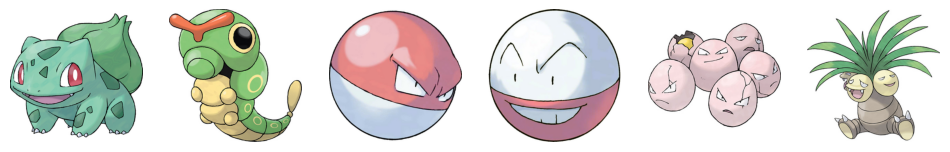

In [17]:
from datasets import load_dataset
import matplotlib.pyplot as plt

CANDIDATES = [
    "reach-vb/pokemon-blip-captions",
    "diffusers/pokemon-gpt4-captions",
]

ds = None
for name in CANDIDATES:
    try:
        ds = load_dataset(name, split="train")
        CFG["dataset"] = name
        print("Dataset cargado:", name)
        break
    except Exception as e:
        print(f"No se pudo cargar {name}: {type(e).__name__}")

if ds is None:
    raise RuntimeError("Ningún candidato cargó. Revisa que Internet esté activado en Kaggle.")

cols = ds.column_names
img_key = "image" if "image" in cols else next(c for c in cols if "im" in c.lower())
txt_key = "text" if "text" in cols else next(c for c in cols if c != img_key)
print("Columnas:", cols, "| usando:", img_key, txt_key)

if CFG["max_images"]:
    ds = ds.select(range(CFG["max_images"]))

def center_square(img, res):
    img = img.convert("RGB")
    w, h = img.size
    s = min(w, h)
    l, t = (w - s) // 2, (h - s) // 2
    return img.crop((l, t, l + s, t + s)).resize((res, res), Image.LANCZOS)

IMGS = torch.stack([
    torch.from_numpy(np.array(center_square(x[img_key], CFG["res"]))).permute(2, 0, 1)
    for x in ds
])  # N,3,R,R uint8
CAPTIONS = [x[txt_key] for x in ds]
N = len(CAPTIONS)
print("Imágenes:", tuple(IMGS.shape), "| ejemplo caption:", CAPTIONS[0])

fig, axs = plt.subplots(1, 6, figsize=(12, 2.5))
for i, ax in enumerate(axs):
    ax.imshow(IMGS[i].permute(1, 2, 0).numpy()); ax.axis("off")
plt.show()

In [18]:
tok, tenc = load_text_encoder(CFG["text_encoder"], DEV)
embs, masks = [], []
for i in range(0, N, 64):
    e, m = encode_text(tok, tenc, CAPTIONS[i:i + 64], DEV, CFG["txt_len"])
    embs.append(e); masks.append(m)
TXT = torch.cat(embs).half()     # N, 77, 512
MASK = torch.cat(masks)          # N, 77
del tenc; torch.cuda.empty_cache()
print("Embeddings de texto:", tuple(TXT.shape))

Loading weights:   0%|          | 0/75 [00:00<?, ?it/s]

[transformers] T5EncoderModel LOAD REPORT from: google/flan-t5-small
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embeddings de texto: (833, 77, 512)


In [19]:
vae = AutoencoderKL.from_pretrained(CFG["vae"]).to(DEV).eval()
lat_chunks = []
with torch.no_grad():
    for i in range(0, N, 16):
        x = IMGS[i:i + 16].to(DEV).float() / 127.5 - 1
        z = vae.encode(x).latent_dist.mean * SCALE
        zf = vae.encode(torch.flip(x, dims=[-1])).latent_dist.mean * SCALE
        lat_chunks.append(torch.stack([z, zf], 1).half().cpu())  # original + flip
LATS = torch.cat(lat_chunks)     # N, 2, 4, L, L
del vae; torch.cuda.empty_cache()
print("Latentes:", tuple(LATS.shape))

Latentes: (833, 2, 4, 32, 32)


In [31]:
model = CoreDenoiser(lat=L, dim=CFG["dim"], groups=CFG["groups"], heads=CFG["heads"],
                     txt_dim=CFG["txt_dim"], steps=STEPS).to(DEV)
n_params = sum(p.numel() for p in model.parameters())
print(f"Parámetros del CORE: {n_params/1e6:.1f}M")

Parámetros del CORE: 70.9M


In [ ]:
B = CFG["batch"]
opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], betas=(0.9, 0.99), weight_decay=0.01)
scaler = torch.amp.GradScaler("cuda")
net = torch.nn.DataParallel(model) if torch.cuda.device_count() > 1 else model

steps_per_epoch = N // B
total = CFG["epochs"] * steps_per_epoch
warm = max(1, total // 10)
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(s, total) / total)))

losses = []
for ep in range(CFG["epochs"]):
    model.train()
    perm = torch.randperm(N)
    for it in range(steps_per_epoch):
        idx = perm[it * B:(it + 1) * B]
        f = torch.randint(0, 2, (len(idx),))
        x0 = LATS[idx, f].to(DEV).float()
        txt = TXT[idx].to(DEV).float()
        m = MASK[idx].to(DEV)

        # Classifier-free guidance: a veces se quita el texto
        drop = torch.rand(len(idx), device=DEV) < CFG["cfg_drop"]
        txt = txt.masked_fill(drop[:, None, None], 0.0)
        m = m | drop[:, None]

        # Paso discreto k in [0, STEPS) -> nivel de ruido t = 1 - k/STEPS
        k = torch.randint(0, STEPS, (len(idx),), device=DEV)
        t = (1 - k.float() / STEPS)[:, None, None, None]
        eps = torch.randn_like(x0)
        xt = (1 - t) * x0 + t * eps

        with torch.autocast("cuda", dtype=torch.float16):
            pred = net(xt, k, txt, m)
        loss = F.mse_loss(pred.float(), x0)

        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        sched.step()
        losses.append(loss.item())

        if (it + 1) % 20 == 0 or it == steps_per_epoch - 1:
            print(f"época {ep+1}/{CFG['epochs']} paso {it+1}/{steps_per_epoch} "
                  f"loss {np.mean(losses[-20:]):.4f} lr {sched.get_last_lr()[0]:.2e}")

    torch.save(model.state_dict(), WORK / "ckpt.pt")  # checkpoint por época
print("Entrenamiento terminado.")

época 1/100 paso 20/26 loss 1.0117 lr 1.62e-05
época 1/100 paso 26/26 loss 0.8803 lr 2.08e-05
época 2/100 paso 20/26 loss 0.4479 lr 3.61e-05
época 2/100 paso 26/26 loss 0.4001 lr 4.07e-05
época 3/100 paso 20/26 loss 0.3330 lr 5.60e-05
época 3/100 paso 26/26 loss 0.3223 lr 6.06e-05
época 4/100 paso 20/26 loss 0.2901 lr 7.59e-05
época 4/100 paso 26/26 loss 0.2798 lr 8.05e-05
época 5/100 paso 20/26 loss 0.2406 lr 9.56e-05
época 5/100 paso 26/26 loss 0.2447 lr 1.00e-04
época 6/100 paso 20/26 loss 0.2393 lr 1.15e-04
época 6/100 paso 26/26 loss 0.2259 lr 1.20e-04
época 7/100 paso 20/26 loss 0.2316 lr 1.35e-04
época 7/100 paso 26/26 loss 0.2352 lr 1.39e-04
época 8/100 paso 20/26 loss 0.2293 lr 1.54e-04
época 8/100 paso 26/26 loss 0.2243 lr 1.58e-04
época 9/100 paso 20/26 loss 0.2258 lr 1.73e-04
época 9/100 paso 26/26 loss 0.2220 lr 1.77e-04
época 10/100 paso 20/26 loss 0.2189 lr 1.92e-04
época 10/100 paso 26/26 loss 0.2212 lr 1.95e-04
época 11/100 paso 20/26 loss 0.2252 lr 1.94e-04
época 11/1

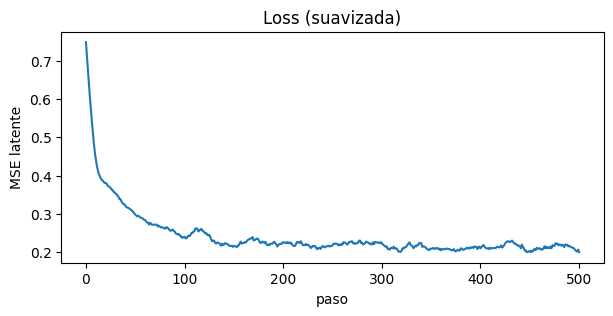

In [27]:
plt.figure(figsize=(7, 3))
plt.plot(np.convolve(losses, np.ones(20) / 20, mode="valid"))
plt.title("Loss (suavizada)"); plt.xlabel("paso"); plt.ylabel("MSE latente")
plt.show()

Loading weights:   0%|          | 0/75 [00:00<?, ?it/s]

[transformers] T5EncoderModel LOAD REPORT from: google/flan-t5-small
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


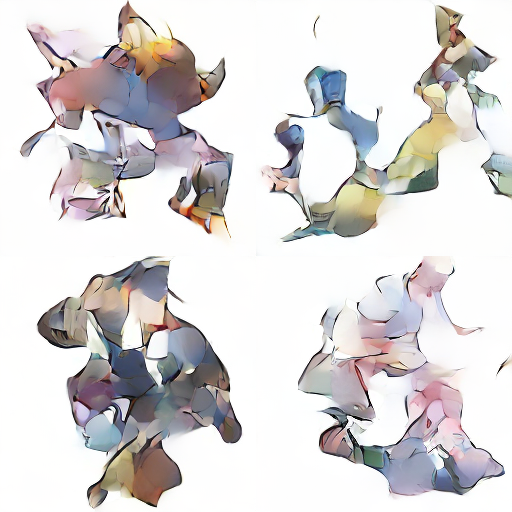

In [28]:
def grid(arrs, cols=2):
    h, w, _ = arrs[0].shape
    rows = (len(arrs) + cols - 1) // cols
    canvas = np.zeros((rows * h, cols * w, 3), np.uint8)
    for i, a in enumerate(arrs):
        r, c = divmod(i, cols)
        canvas[r * h:(r + 1) * h, c * w:(c + 1) * w] = a
    return Image.fromarray(canvas)

PROMPTS = [
    "a drawing of a green pokemon with red eyes",
    "a blue water pokemon",
    "a yellow electric pokemon with a tail",
    "a pink round pokemon",
]
tok, tenc = load_text_encoder(CFG["text_encoder"], DEV)
e, mk = encode_text(tok, tenc, PROMPTS, DEV, CFG["txt_len"])
del tenc; torch.cuda.empty_cache()

z = sample(model, e, mk, lat=L, steps=STEPS, cfg=CFG["cfg_scale"], seed=CFG["seed"], device=DEV)
vae = AutoencoderKL.from_pretrained(CFG["vae"]).to(DEV).eval()
samples = decode(vae, z)
g = grid(list(samples), cols=2)
g.save(WORK / "samples.png")
display(g)

In [29]:
EXP = WORK / "export"
shutil.rmtree(EXP, ignore_errors=True)
EXP.mkdir(parents=True)

# Pesos
save_file({k: v.contiguous() for k, v in model.state_dict().items()}, EXP / "core.safetensors")

# Configuración
cfg_out = {**CFG, "steps": STEPS, "n_params": n_params}
(EXP / "config.json").write_text(json.dumps(cfg_out, indent=2))

# Código de la arquitectura y script de inferencia
shutil.copy("/kaggle/working/coder_lib.py", EXP / "coder_lib.py")

RUN_SCRIPT = '''import sys, json
from pathlib import Path
import torch
from PIL import Image
from safetensors.torch import load_file
from diffusers import AutoencoderKL
from coder_lib import CoreDenoiser, load_text_encoder, encode_text, sample, decode, SCALE

HERE = Path(__file__).parent
cfg = json.load(open(HERE / "config.json"))
dev = "cuda"

core = CoreDenoiser(lat=cfg["lat"], dim=cfg["dim"], groups=cfg["groups"], heads=cfg["heads"],
                    txt_dim=cfg["txt_dim"], steps=cfg["steps"]).to(dev)
core.load_state_dict(load_file(HERE / "core.safetensors", device=dev))

tok, tenc = load_text_encoder(cfg["text_encoder"], dev)
vae = AutoencoderKL.from_pretrained(cfg["vae"]).to(dev).eval()

prompt = sys.argv[1] if len(sys.argv) > 1 else "a blue water pokemon"
e, m = encode_text(tok, tenc, [prompt], dev, cfg["txt_len"])
z = sample(core, e, m, lat=cfg["lat"], steps=cfg["steps"], cfg=cfg["cfg_scale"], seed=0, device=dev)
img = decode(vae, z)[0]
Image.fromarray(img).save(HERE / "out.png")
print("Imagen guardada en out.png")
'''
(EXP / "run_inference.py").write_text(RUN_SCRIPT)

# Muestras de prueba
(EXP / "samples").mkdir()
g.save(EXP / "samples" / "samples.png")

README = f"""# CODER (prototipo texto->imagen)

Arquitectura: Encoder de texto congelado ({CFG['text_encoder']}) -> CORE híbrido
(bloques convolucionales y de atención en relación 2:1) sobre una rejilla latente
{L}x{L}x4 -> VAE congelado ({CFG['vae']}) para decodificar.

- Parámetros del core: {n_params/1e6:.1f}M
- Pasos de muestreo: {STEPS} (k = 0..{STEPS-1})
- Resolución: {CFG['res']}x{CFG['res']}
- Dataset: {CFG['dataset']}
- Épocas de entrenamiento: {CFG['epochs']}

## Uso
pip install diffusers transformers safetensors accelerate sentencepiece
python run_inference.py "a red fire pokemon"
"""
(EXP / "README.md").write_text(README)

# Zip listo para descargar
zip_path = shutil.make_archive("/kaggle/working/coder_model", "zip", EXP)
print("Exportado:", zip_path)
print(os.listdir(EXP))

Exportado: /kaggle/working/coder_model.zip
['run_inference.py', 'samples', 'README.md', 'coder_lib.py', 'config.json', 'core.safetensors']
